**IMPORTING REQUIRED LIBRARIES**



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

In [2]:
df=pd.read_csv("bank-additional-full.csv",sep=';')

In [3]:
df.head()

,age,job,marital,education,default,housing,loan,contact,month,day_of_week,...,campaign,pdays,previous,poutcome,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
0,56,housemaid,married,basic.4y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
1,57,services,married,high.school,unknown,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
2,37,services,married,high.school,no,yes,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
3,40,admin.,married,basic.6y,no,no,no,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no
4,56,services,married,high.school,no,no,yes,telephone,may,mon,...,1,999,0,nonexistent,1.1,93.994,-36.4,4.857,5191.0,no


In [4]:
df.info()
df.shape

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 41188 entries, 0 to 41187
Data columns (total 21 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   age             41188 non-null  int64  
 1   job             41188 non-null  object 
 2   marital         41188 non-null  object 
 3   education       41188 non-null  object 
 4   default         41188 non-null  object 
 5   housing         41188 non-null  object 
 6   loan            41188 non-null  object 
 7   contact         41188 non-null  object 
 8   month           41188 non-null  object 
 9   day_of_week     41188 non-null  object 
 10  duration        41188 non-null  int64  
 11  campaign        41188 non-null  int64  
 12  pdays           41188 non-null  int64  
 13  previous        41188 non-null  int64  
 14  poutcome        41188 non-null  object 
 15  emp.var.rate    41188 non-null  float64
 16  cons.price.idx  41188 non-null  float64
 17  cons.conf.idx   41188 non-null 

(41188, 21)

In [5]:
df.describe()

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed
count,41188.00000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000,41188.000000
mean,40.02406,258.285010,2.567593,962.475454,0.172963,0.081886,93.575664,-40.502600,3.621291,5167.035911
std,10.42125,259.279249,2.770014,186.910907,0.494901,1.570960,0.578840,4.628198,1.734447,72.251528
min,17.00000,0.000000,1.000000,0.000000,0.000000,-3.400000,92.201000,-50.800000,0.634000,4963.600000
25%,32.00000,102.000000,1.000000,999.000000,0.000000,-1.800000,93.075000,-42.700000,1.344000,5099.100000
50%,38.00000,180.000000,2.000000,999.000000,0.000000,1.100000,93.749000,-41.800000,4.857000,5191.000000
75%,47.00000,319.000000,3.000000,999.000000,0.000000,1.400000,93.994000,-36.400000,4.961000,5228.100000
max,98.00000,4918.000000,56.000000,999.000000,7.000000,1.400000,94.767000,-26.900000,5.045000,5228.100000


In [6]:
df.isnull().sum()

age               0
job               0
marital           0
education         0
default           0
housing           0
loan              0
contact           0
month             0
day_of_week       0
duration          0
campaign          0
pdays             0
previous          0
poutcome          0
emp.var.rate      0
cons.price.idx    0
cons.conf.idx     0
euribor3m         0
nr.employed       0
y                 0
dtype: int64

In [7]:
df.duplicated().sum()

np.int64(12)

In [8]:
df.drop_duplicates(inplace=True)

**Understanding the Target Variable**

In [9]:
df.value_counts('y',normalize=True)*100


y
no     88.733728
yes    11.266272
Name: proportion, dtype: float64

**EDA between categorical values**


  **Establishing relation between job categories and subscription rate**

In [10]:
df['y']=(df['y']=='yes').astype(int) #to convert into binary values

x=(df.groupby('job')['y'].mean()*100).sort_values(ascending=False)
x

job
student          31.428571
retired          25.261932
unemployed       14.201183
admin.           12.966695
management       11.217510
unknown          11.212121
technician       10.832468
self-employed    10.485574
housemaid        10.000000
entrepreneur      8.516484
services          8.142173
blue-collar       6.895061
Name: y, dtype: float64

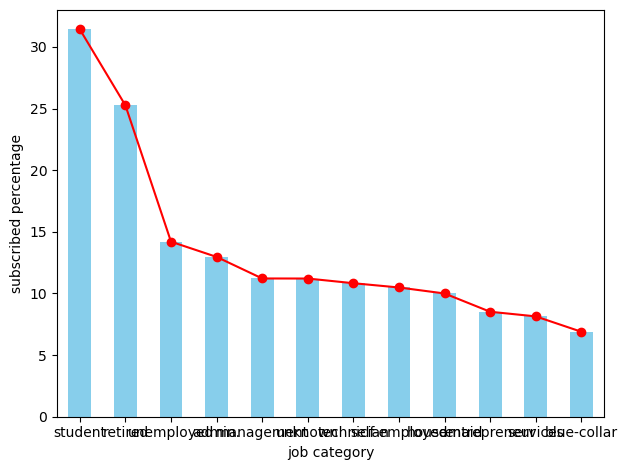

In [11]:
ax=x.plot(kind='bar',color='skyblue')
x.plot(kind='line',ax=ax,marker='o',color='red')
plt.xlabel('job category')
plt.ylabel('subscribed percentage')
plt.tight_layout()
plt.show()

**Establishing relation between subscription and Education**

In [12]:
df.value_counts('education',normalize=True)*100


education
university.degree      29.541480
high.school            23.100835
basic.9y               14.680882
professional.course    12.725860
basic.4y               10.141830
basic.6y                5.563921
unknown                 4.201477
illiterate              0.043715
Name: proportion, dtype: float64

In [13]:
y=(df.groupby('education')['y'].mean()*100).sort_values(ascending=False)
y


education
illiterate             22.222222
unknown                14.508671
university.degree      13.720816
professional.course    11.354962
high.school            10.838940
basic.4y               10.249042
basic.6y                8.206024
basic.9y                7.824648
Name: y, dtype: float64

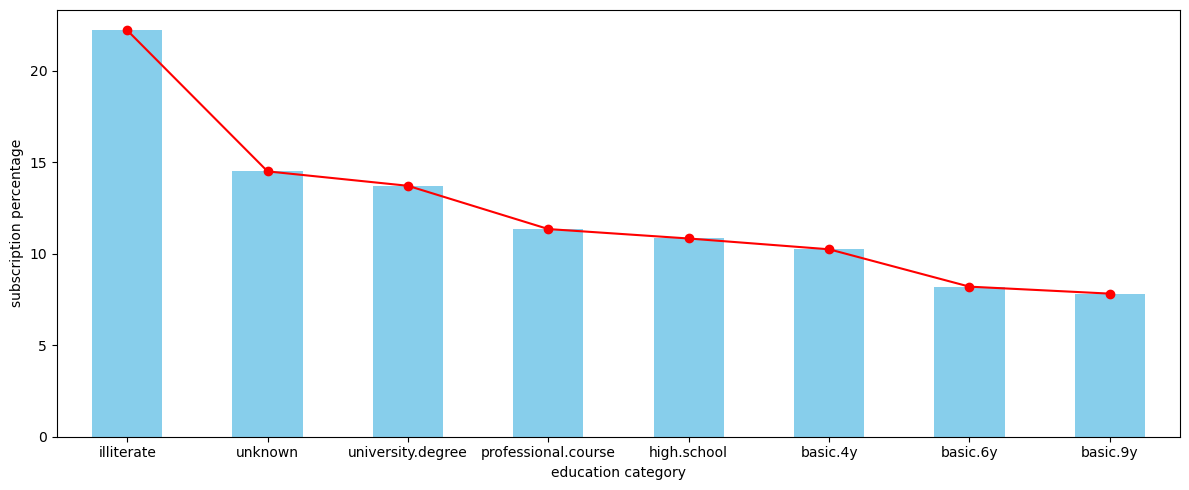

In [14]:
ax=y.plot(kind='bar',color='skyblue',figsize=(12,5))
y.plot(kind='line',marker='o',color='red',ax=ax)
plt.xlabel('education category')
plt.ylabel('subscription percentage')
plt.tight_layout()
plt.show()


**Establishing relation between subscription and MaritalStatus**

In [15]:
df.value_counts('marital',normalize=True)*100

marital
married     60.523120
single      28.084321
divorced    11.198271
unknown      0.194288
Name: proportion, dtype: float64

In [16]:
z=(df.groupby('marital')['y'].mean()*100).sort_values(ascending=False)
z

marital
unknown     15.000000
single      14.008993
divorced    10.323140
married     10.156093
Name: y, dtype: float64

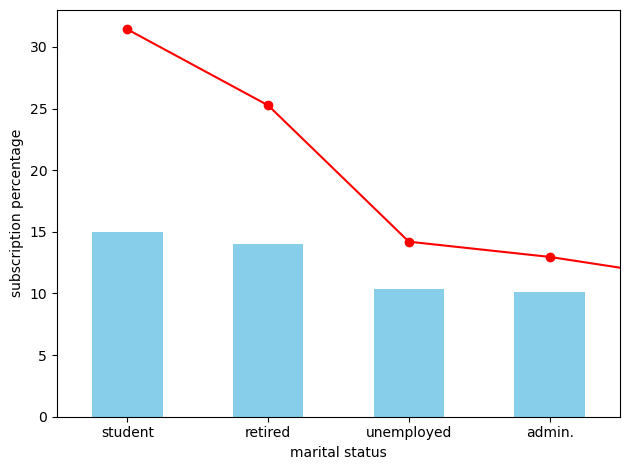

In [17]:

ax=z.plot(kind='bar',color='skyblue')
x.plot(kind='line',marker='o',ax=ax,color='red')
plt.xlabel('marital status')
plt.ylabel('subscription percentage')
plt.tight_layout()
plt.show()


**Establishing relation between subscription and ContactMethod**

In [18]:
df.value_counts('contact',normalize=True)*100

contact
cellular     63.47144
telephone    36.52856
Name: proportion, dtype: float64

In [19]:
c=(df.groupby('contact')['y'].mean()*100).sort_values(ascending=False)
c

contact
cellular     14.738856
telephone     5.232365
Name: y, dtype: float64

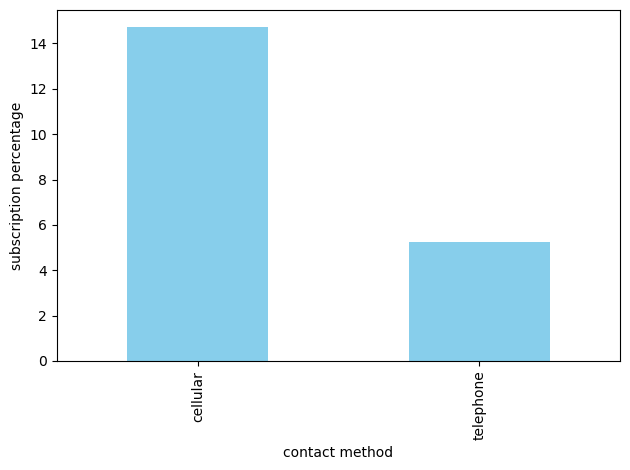

In [20]:

c.plot(kind='bar',color='skyblue')
plt.xlabel('contact method')
plt.ylabel('subscription percentage')
plt.tight_layout()
plt.show()


**Establishing relation between subscription and Campaign Month**

In [21]:
df.value_counts('month',normalize=True)*100

month
may    33.434525
jul    17.410628
aug    14.999029
jun    12.915290
nov     9.957257
apr     6.389644
oct     1.741306
sep     1.384302
mar     1.326015
dec     0.442005
Name: proportion, dtype: float64

In [22]:
m=(df.groupby('month')['y'].mean()*100).sort_values(ascending=False)
m

month
mar    50.549451
dec    48.901099
sep    44.912281
oct    43.933054
apr    20.486507
aug    10.605570
jun    10.511470
nov    10.146341
jul     9.038918
may     6.435680
Name: y, dtype: float64

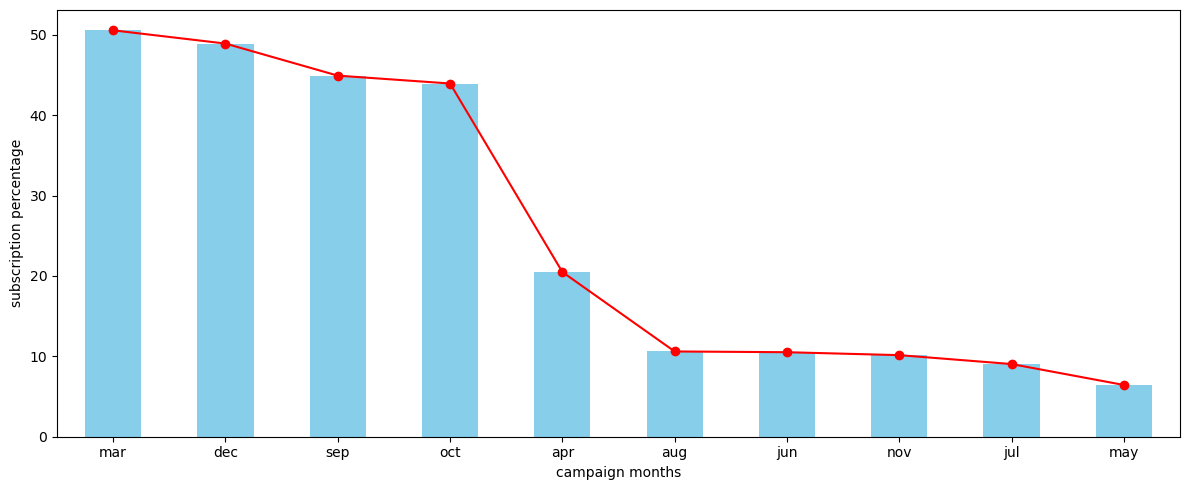

In [23]:
ax=m.plot(kind='bar',color='skyblue',figsize=(12,5))
m.plot(kind='line',marker='o',color='red',ax=ax)
plt.xlabel('campaign months')
plt.ylabel('subscription percentage')
plt.tight_layout()
plt.show()

**EDA between numeric values**

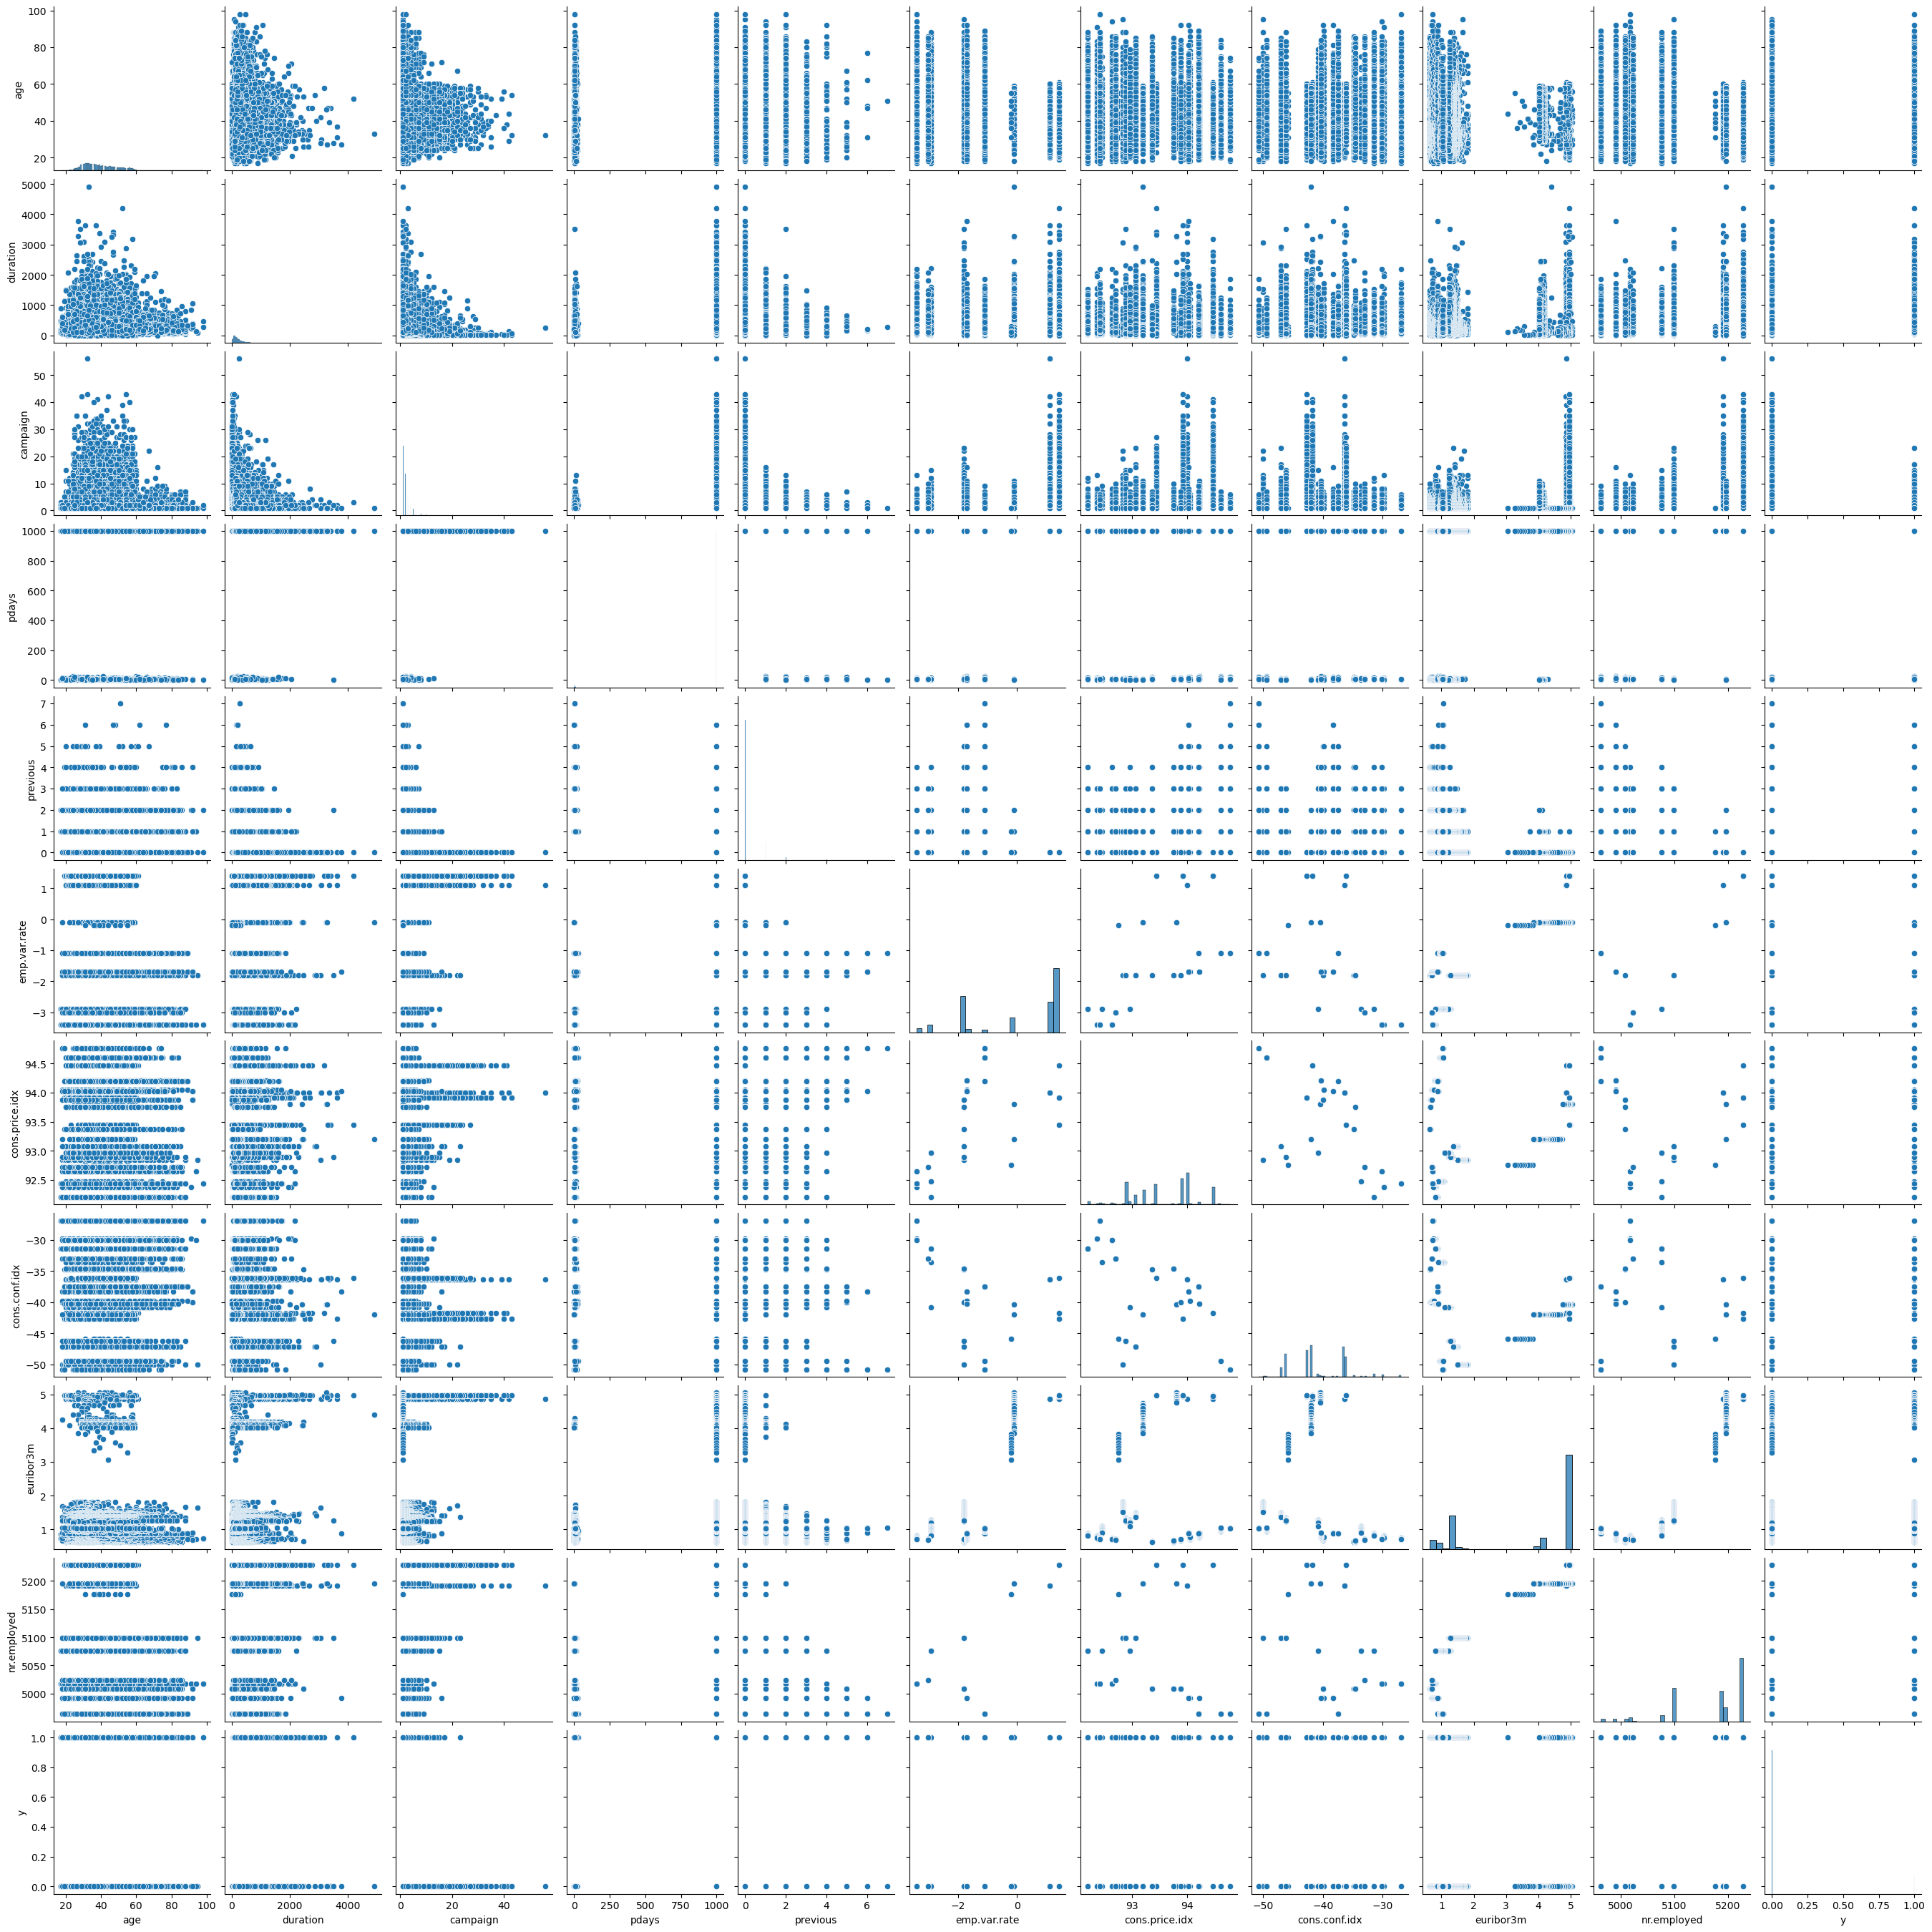

In [24]:
sns.pairplot(df)

In [25]:
df.corr(numeric_only=True)

,age,duration,campaign,pdays,previous,emp.var.rate,cons.price.idx,cons.conf.idx,euribor3m,nr.employed,y
age,1.000000,-0.000808,0.004622,-0.034381,0.024379,-0.000242,0.001009,0.129075,0.010852,-0.017607,0.030381
duration,-0.000808,1.000000,-0.071765,-0.047556,0.020600,-0.027941,0.005303,-0.008126,-0.032861,-0.044672,0.405297
campaign,0.004622,-0.071765,1.000000,0.052606,-0.079182,0.150786,0.127826,-0.013657,0.135169,0.144129,-0.066361
pdays,-0.034381,-0.047556,0.052606,1.000000,-0.587508,0.271063,0.078920,-0.091374,0.296946,0.372659,-0.324948
previous,0.024379,0.020600,-0.079182,-0.587508,1.000000,-0.420587,-0.203197,-0.050929,-0.454571,-0.501411,0.230202
emp.var.rate,-0.000242,-0.027941,0.150786,0.271063,-0.420587,1.000000,0.775293,0.196257,0.972244,0.906949,-0.298289
cons.price.idx,0.001009,0.005303,0.127826,0.078920,-0.203197,0.775293,1.000000,0.059170,0.688180,0.521945,-0.136134
cons.conf.idx,0.129075,-0.008126,-0.013657,-0.091374,-0.050929,0.196257,0.059170,1.000000,0.277864,0.100679,0.054802
euribor3m,0.010852,-0.032861,0.135169,0.296946,-0.454571,0.972244,0.688180,0.277864,1.000000,0.945146,-0.307740
nr.employed,-0.017607,-0.044672,0.144129,0.372659,-0.501411,0.906949,0.521945,0.100679,0.945146,1.000000,-0.354669


<Axes: >

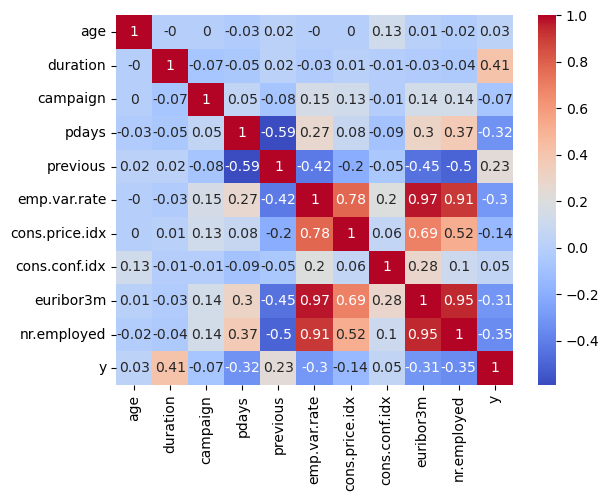

In [26]:
sns.heatmap(data=df.corr(numeric_only=True).round(2),cmap='coolwarm',annot=True)


**TRAIN TEST SPLIT**


In [27]:
from sklearn.model_selection import train_test_split

In [28]:
x=df.drop(columns=['y','duration'])
y=df['y']

x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,stratify=y,random_state=40)

In [29]:
x_train.shape


(32940, 19)

In [30]:
y_train.shape


(32940,)

In [31]:
x_test.shape

(8236, 19)

In [32]:
y_test.shape

(8236,)

**DATA PREPROCESSING**

In [33]:
x_train.dtypes

age                 int64
job                object
marital            object
education          object
default            object
housing            object
loan               object
contact            object
month              object
day_of_week        object
campaign            int64
pdays               int64
previous            int64
poutcome           object
emp.var.rate      float64
cons.price.idx    float64
cons.conf.idx     float64
euribor3m         float64
nr.employed       float64
dtype: object

In [34]:
numeric_features = [
    'age', 'campaign', 'pdays', 'previous',
    'emp.var.rate', 'cons.price.idx', 'cons.conf.idx',
    'euribor3m', 'nr.employed'
]

categorical_features = [
    'job', 'marital', 'education', 'default', 'housing',
    'loan', 'contact', 'month', 'day_of_week', 'poutcome'
]

In [35]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler


In [36]:
numeric_transformer = StandardScaler()

categorical_transformer = OneHotEncoder(handle_unknown='ignore')

In [37]:
preprocessor = ColumnTransformer(
    transformers=[
        ('num', numeric_transformer, numeric_features),
        ('cat', categorical_transformer, categorical_features)
    ]
)

**MACHINE LEARNING**


**LOGISTIC REGRESSION**

In [38]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

In [39]:
lr = Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', LogisticRegression(max_iter=1000))
    ]
)
lr.fit(x_train,y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [40]:
lr_pred=lr.predict(x_test)

In [41]:
from sklearn.metrics import accuracy_score,classification_report,confusion_matrix


In [42]:
print("Accuracy:", accuracy_score(y_test, lr_pred))
print(classification_report(y_test, lr_pred))
print(confusion_matrix(y_test, lr_pred))

Accuracy: 0.8993443419135503
              precision    recall  f1-score   support

           0       0.91      0.99      0.95      7308
           1       0.66      0.22      0.33       928

    accuracy                           0.90      8236
   macro avg       0.78      0.60      0.64      8236
weighted avg       0.88      0.90      0.88      8236

[[7201  107]
 [ 722  206]]


In [70]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score
results = {}

results['Logistic Regression'] = {
    'Accuracy': accuracy_score(y_test, lr_pred),
    'Precision': precision_score(y_test, lr_pred),
    'Recall': recall_score(y_test, lr_pred),
    'F1 Score': f1_score(y_test, lr_pred)
}

**KNN**

In [44]:
from sklearn.neighbors import KNeighborsClassifier

In [45]:
knn=Pipeline(
    steps=[
        ('prepocessing',preprocessor),
        ('classifier',KNeighborsClassifier(n_neighbors=5))
         ]
)
knn.fit(x_train,y_train)
    

,steps,"[('prepocessing', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [46]:
knn_pred=knn.predict(x_test)

In [47]:
print("Accuracy:", accuracy_score(y_test, knn_pred))
print(classification_report(y_test, knn_pred))
print(confusion_matrix(y_test, knn_pred))

Accuracy: 0.8953375424963574
              precision    recall  f1-score   support

           0       0.92      0.97      0.94      7308
           1       0.57      0.30      0.39       928

    accuracy                           0.90      8236
   macro avg       0.74      0.63      0.67      8236
weighted avg       0.88      0.90      0.88      8236

[[7098  210]
 [ 652  276]]


**TUNING THE MODEL FOR RELIABLE OUTPUT**

In [48]:
from sklearn.model_selection import GridSearchCV

In [49]:
param_grid = {
    'classifier__n_neighbors': [1,2,3,4,5,6,7,8,9,10]
}

In [50]:
grid_search = GridSearchCV(
    knn,
    param_grid,
    verbose=3,
    scoring='f1'
)

grid_search.fit(x_train, y_train)



Fitting 5 folds for each of 10 candidates, totalling 50 fits
[CV 1/5] END .........classifier__n_neighbors=1;, score=0.319 total time=   0.5s
[CV 2/5] END .........classifier__n_neighbors=1;, score=0.328 total time=   0.4s
[CV 3/5] END .........classifier__n_neighbors=1;, score=0.341 total time=   0.4s
[CV 4/5] END .........classifier__n_neighbors=1;, score=0.341 total time=   0.3s
[CV 5/5] END .........classifier__n_neighbors=1;, score=0.313 total time=   0.4s
[CV 1/5] END .........classifier__n_neighbors=2;, score=0.255 total time=   0.5s
[CV 2/5] END .........classifier__n_neighbors=2;, score=0.266 total time=   0.4s
[CV 3/5] END .........classifier__n_neighbors=2;, score=0.268 total time=   0.4s
[CV 4/5] END .........classifier__n_neighbors=2;, score=0.249 total time=   0.3s
[CV 5/5] END .........classifier__n_neighbors=2;, score=0.263 total time=   0.4s
[CV 1/5] END .........classifier__n_neighbors=3;, score=0.360 total time=   0.4s
[CV 2/5] END .........classifier__n_neighbors=3;

,estimator,Pipeline(step...lassifier())])
,param_grid,"{'classifier__n_neighbors': [1, 2, ...]}"
,scoring,'f1'
,n_jobs,None
,refit,True
,cv,None
,verbose,3
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [51]:

grid_search.best_score_

np.float64(0.37093936068973743)

In [52]:
grid_search.best_params_

{'classifier__n_neighbors': 9}

**EVALUATING TUNED MODEL**

In [53]:
knn=Pipeline(
    steps=[
        ('prepocessing',preprocessor),
        ('classifier',KNeighborsClassifier(n_neighbors=9))
         ]
)
knn.fit(x_train,y_train)
    

,steps,"[('prepocessing', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [54]:
knn_pred=knn.predict(x_test)

In [55]:
print("Accuracy:", accuracy_score(y_test, knn_pred))
print(classification_report(y_test, knn_pred))
print(confusion_matrix(y_test, knn_pred))

Accuracy: 0.8963088878096164
              precision    recall  f1-score   support

           0       0.91      0.98      0.94      7308
           1       0.59      0.27      0.37       928

    accuracy                           0.90      8236
   macro avg       0.75      0.62      0.66      8236
weighted avg       0.88      0.90      0.88      8236

[[7132  176]
 [ 678  250]]


In [71]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score



results['KNN'] = {
    'Accuracy': accuracy_score(y_test, knn_pred),
    'Precision': precision_score(y_test, knn_pred),
    'Recall': recall_score(y_test, knn_pred),
    'F1 Score': f1_score(y_test, knn_pred)
}

**SVM**

In [57]:
from sklearn.svm import SVC

In [58]:
svm= Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', SVC())
    ]
)


In [59]:
svm.fit(x_train,y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [60]:
svm_pred=svm.predict(x_test)

In [61]:
print("Accuracy:", accuracy_score(y_test, svm_pred))
print(classification_report(y_test, svm_pred))
print(confusion_matrix(y_test, svm_pred))

Accuracy: 0.9025012141816415
              precision    recall  f1-score   support

           0       0.91      0.98      0.95      7308
           1       0.68      0.26      0.37       928

    accuracy                           0.90      8236
   macro avg       0.80      0.62      0.66      8236
weighted avg       0.89      0.90      0.88      8236

[[7195  113]
 [ 690  238]]


**FINE TUNING FOR RELIABLE OUTPUT**

In [62]:
para_grid={'classifier__C':[100,1000],'classifier__gamma':[0.001,0.0001]}

In [63]:
gris=GridSearchCV(
    svm,para_grid,verbose=3,scoring='f1',cv=3)
gris.fit(x_train,y_train)

Fitting 3 folds for each of 4 candidates, totalling 12 fits
[CV 1/3] END classifier__C=100, classifier__gamma=0.001;, score=0.283 total time=  46.2s
[CV 2/3] END classifier__C=100, classifier__gamma=0.001;, score=0.293 total time=  47.0s
[CV 3/3] END classifier__C=100, classifier__gamma=0.001;, score=0.308 total time=  49.9s
[CV 1/3] END classifier__C=100, classifier__gamma=0.0001;, score=0.308 total time=  26.3s
[CV 2/3] END classifier__C=100, classifier__gamma=0.0001;, score=0.309 total time=  27.6s
[CV 3/3] END classifier__C=100, classifier__gamma=0.0001;, score=0.322 total time=  28.9s
[CV 1/3] END classifier__C=1000, classifier__gamma=0.001;, score=0.293 total time= 1.6min
[CV 2/3] END classifier__C=1000, classifier__gamma=0.001;, score=0.300 total time= 1.5min
[CV 3/3] END classifier__C=1000, classifier__gamma=0.001;, score=0.309 total time= 1.5min
[CV 1/3] END classifier__C=1000, classifier__gamma=0.0001;, score=0.308 total time=  38.7s
[CV 2/3] END classifier__C=1000, classifie

,estimator,"Pipeline(step...ier', SVC())])"
,param_grid,"{'classifier__C': [100, 1000], 'classifier__gamma': [0.001, 0.0001]}"
,scoring,'f1'
,n_jobs,None
,refit,True
,cv,3
,verbose,3
,pre_dispatch,'2*n_jobs'
,error_score,nan
,return_train_score,False
,transformers,"[('num', ...), ('cat', ...)]"


In [64]:
gris.best_params_

{'classifier__C': 100, 'classifier__gamma': 0.0001}

**EVALUATING TUNED MODEL**

In [65]:
svm= Pipeline(
    steps=[
        ('preprocessor', preprocessor),
        ('classifier', SVC(C=100,gamma=0.0001))
    ]
)
svm.fit(x_train,y_train)

,steps,"[('preprocessor', ...), ('classifier', ...)]"
,transform_input,None
,memory,None
,verbose,False
,transformers,"[('num', ...), ('cat', ...)]"
,remainder,'drop'
,sparse_threshold,0.3
,n_jobs,None
,transformer_weights,None
,verbose,False
,verbose_feature_names_out,True


In [66]:
svm_pred=svm.predict(x_test)

In [67]:
print("Accuracy:", accuracy_score(y_test, svm_pred))
print(classification_report(y_test, svm_pred))
print(confusion_matrix(y_test, svm_pred))

Accuracy: 0.8976444876153472
              precision    recall  f1-score   support

           0       0.91      0.98      0.94      7308
           1       0.64      0.21      0.32       928

    accuracy                           0.90      8236
   macro avg       0.77      0.60      0.63      8236
weighted avg       0.88      0.90      0.87      8236

[[7195  113]
 [ 730  198]]


In [72]:


results['SVM'] = {
    'Accuracy': accuracy_score(y_test, svm_pred),
    'Precision': precision_score(y_test, svm_pred),
    'Recall': recall_score(y_test, svm_pred),
    'F1 Score': f1_score(y_test, svm_pred)
}

In [76]:
res=pd.DataFrame(results)
res

,Logistic Regression,KNN,SVM
Accuracy,0.899344,0.896309,0.897644
Precision,0.658147,0.586854,0.636656
Recall,0.221983,0.269397,0.213362
F1 Score,0.331990,0.369276,0.319613


In [78]:
import joblib

joblib.dump(knn, 'bank_marketing_knn.pkl')

['bank_marketing_knn.pkl']